# **Results analysis: LSTM forecasting and carbon-tax dispatch**

**Contents**
1. Data, quality checks and the split
2. Forecast skill vs baselines
3. Forecast examples and training curves
4. Carbon-tax scenarios and the coal-to-gas switch
5. Forecast-driven vs perfect-foresight dispatch
6. Verification checks (energy balance, analytical break-even)
7. High-renewables sensitivity (battery role)

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import config as cfg
import data_utils as du
from build_network import breakeven_tax, thermal_cost, emissions_per_mwh_el

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.options.display.float_format = "{:,.2f}".format


## **1. Data:** five years, quality checks, capacity growth and the split

In [2]:
report = {}
frame = du.build_frame(report=report)
print(f"Rows in memory: {len(frame):,}  (years {cfg.MODEL_YEARS[0]}-{cfg.MODEL_YEARS[1]})")
print(f"Approx. DataFrame size: {frame.memory_usage(deep=True).sum() / 1e6:.1f} MB")
print(report)

Rows in memory: 43,824  (years 2015-2019)
Approx. DataFrame size: 4.9 MB
{'rows': 43824, 'years': '2015-2019', 'nan_in_file': 177, 'flagged_missing': {'solar_mw': 103, 'wind_mw': 74}, 'missing_after_interpolation': {'solar_mw': 79, 'wind_mw': 54}, 'capacity_source': 'OPSD installed capacity'}


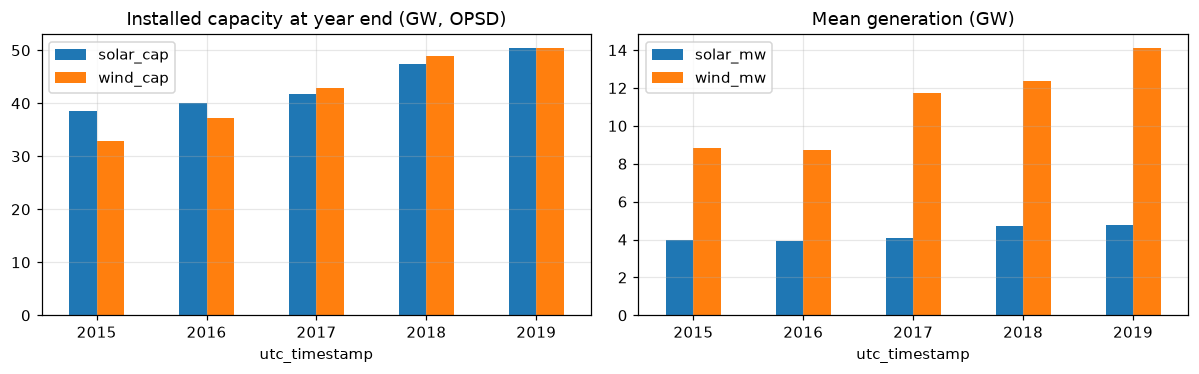

Capacity growth 2015 to 2019: solar 31%, wind 54%


In [3]:
cap = frame[["solar_cap", "wind_cap"]].resample("YE").last() / 1e3
gen = frame[["solar_mw", "wind_mw"]].resample("YE").mean() / 1e3
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
cap.plot.bar(ax=axes[0], rot=0); axes[0].set_title("Installed capacity at year end (GW, OPSD)")
gen.plot.bar(ax=axes[1], rot=0); axes[1].set_title("Mean generation (GW)")
for ax in axes: ax.set_xticklabels([d.year for d in cap.index])
plt.tight_layout(); plt.show()
growth = (cap.iloc[-1] / cap.iloc[0] - 1) * 100
print(f"Capacity growth 2015 to 2019: solar {growth['solar_cap']:.0f}%, wind {growth['wind_cap']:.0f}%")


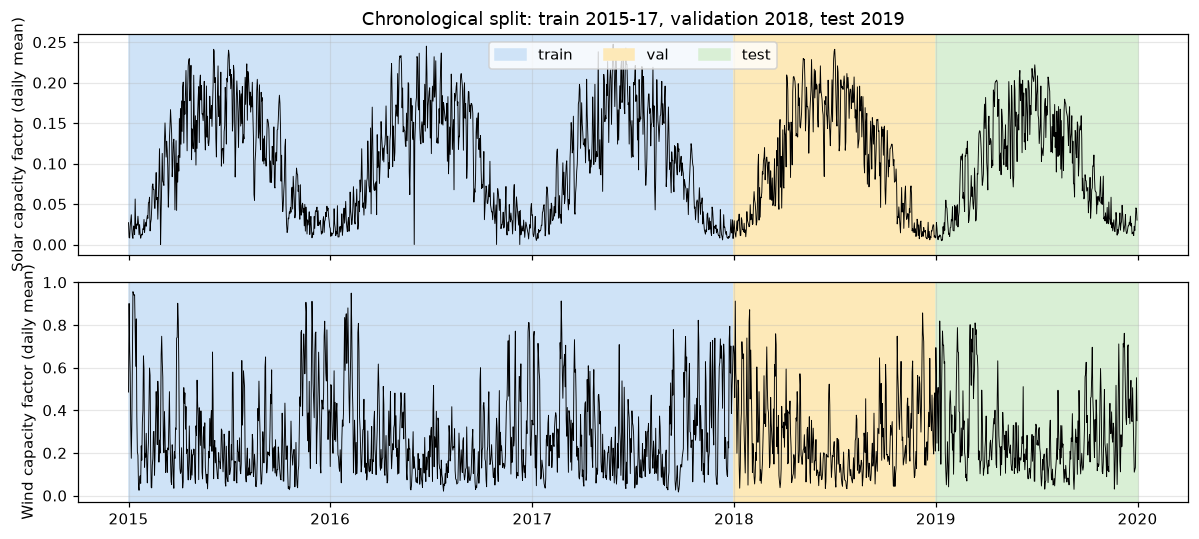

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
daily = frame[["solar_pu", "wind_pu"]].resample("D").mean()
colors = {"train": "#cfe3f7", "val": "#fde9b8", "test": "#d9efd5"}
for ax, col, title in zip(axes, ["solar_pu", "wind_pu"], ["Solar", "Wind"]):
    for name, (a, b) in cfg.SPLITS.items():
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=colors[name], label=name)
    ax.plot(daily.index, daily[col], color="k", lw=0.6)
    ax.set_ylabel(f"{title} capacity factor (daily mean)")
axes[0].legend(ncol=3, loc="upper center")
axes[0].set_title("Chronological split: train 2015-17, validation 2018, test 2019")
plt.tight_layout(); plt.show()


Installed capacity grew strongly over the period, so raw MW values drift upwards. All modelling therefore uses
**capacity factors** (generation divided by installed capacity), which removes most of that trend. The test year is a full
calendar year, so every season is evaluated.

## **2. Forecast skill vs baselines (test year 2019)**

In [5]:
skill = pd.read_csv(cfg.SKILL_CSV)
order = ["Persistence", "Seasonal naive", "Gradient boosting", "LSTM"]
for s in cfg.TARGETS:
    print(f"\n{s.upper()}: MAE (MW)")
    display(skill[skill.series == s].pivot(index="model", columns="horizon_h", values="MAE_MW").loc[order])



SOLAR: MAE (MW)


horizon_h,1,3,6,24
model,,,,
Persistence,"1,295.37","3,772.21","6,838.52","1,139.66"
Seasonal naive,"1,137.83","1,137.83","1,137.83","1,139.66"
Gradient boosting,506.83,"1,866.69","1,060.48","1,069.47"
LSTM,206.74,575.14,914.46,"1,035.00"



WIND: MAE (MW)


horizon_h,1,3,6,24
model,,,,
Persistence,772.66,"2,076.48","3,506.67","6,836.09"
Seasonal naive,"6,866.07","6,863.13","6,855.73","6,836.09"
Gradient boosting,504.99,"1,588.76","2,976.63","6,371.81"
LSTM,450.98,"1,424.86","2,768.08","6,232.30"


In [6]:
lstm = skill[skill.model == "LSTM"].copy()
lstm["skill 95% CI"] = lstm.apply(lambda r: f"[{r.skill_ci_low:+.3f}, {r.skill_ci_high:+.3f}]", axis=1)
gbm = skill[skill.model == "Gradient boosting"].set_index(["series", "horizon_h"])["skill_vs_persistence"]
lstm["GBM skill"] = [gbm[(r.series, r.horizon_h)] for r in lstm.itertuples()]
display(lstm[["series", "horizon_h", "MAE_MW", "nMAE_pct_cap", "skill_vs_persistence", "skill 95% CI", "GBM skill"]]
        .rename(columns={"skill_vs_persistence": "LSTM skill"}).reset_index(drop=True))


,series,horizon_h,MAE_MW,nMAE_pct_cap,LSTM skill,skill 95% CI,GBM skill
0,solar,1,206.74,0.42,0.84,"[+0.832, +0.849]",0.61
1,solar,3,575.14,1.16,0.85,"[+0.837, +0.857]",0.51
2,solar,6,914.46,1.85,0.87,"[+0.855, +0.875]",0.84
3,solar,24,"1,035.00",2.09,0.09,"[+0.042, +0.139]",0.06
4,wind,1,450.98,0.91,0.42,"[+0.398, +0.434]",0.35
5,wind,3,"1,424.86",2.87,0.31,"[+0.292, +0.336]",0.23
6,wind,6,"2,768.08",5.58,0.21,"[+0.184, +0.235]",0.15
7,wind,24,"6,232.30",12.56,0.09,"[+0.049, +0.133]",0.07


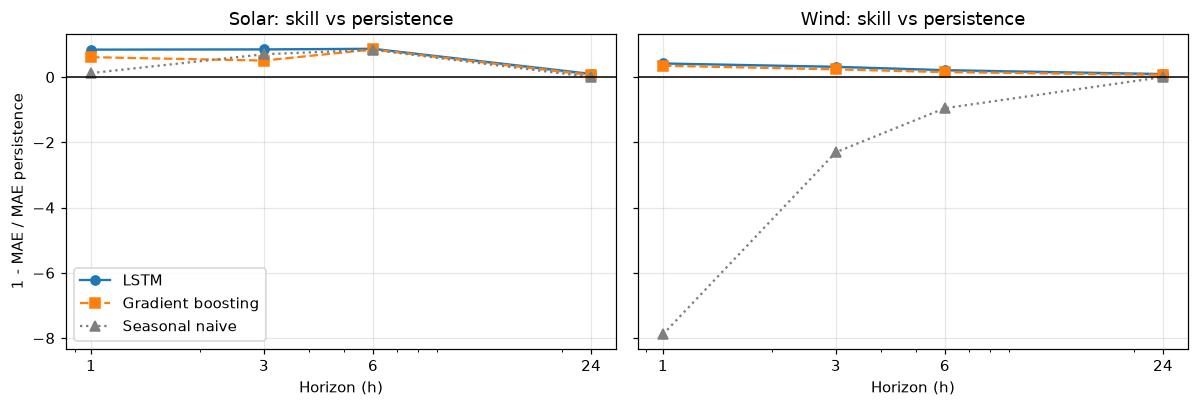

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
styles = {"LSTM": ("tab:blue", "o-"), "Gradient boosting": ("tab:orange", "s--"), "Seasonal naive": ("tab:gray", "^:")}
for ax, s in zip(axes, cfg.TARGETS):
    for name, (c, st) in styles.items():
        d = skill[(skill.series == s) & (skill.model == name)].sort_values("horizon_h")
        ax.plot(d.horizon_h, d.skill_vs_persistence, st, color=c, label=name)
        if name == "LSTM":
            ax.fill_between(d.horizon_h, d.skill_ci_low, d.skill_ci_high, color=c, alpha=0.15)
    ax.axhline(0, color="k", lw=1); ax.set_xscale("log"); ax.set_xticks(cfg.HORIZONS); ax.set_xticklabels(cfg.HORIZONS)
    ax.set_title(f"{s.capitalize()}: skill vs persistence"); ax.set_xlabel("Horizon (h)")
axes[0].set_ylabel("1 - MAE / MAE persistence"); axes[0].legend()
plt.tight_layout(); plt.show()


## **3. Forecast examples and training curves**

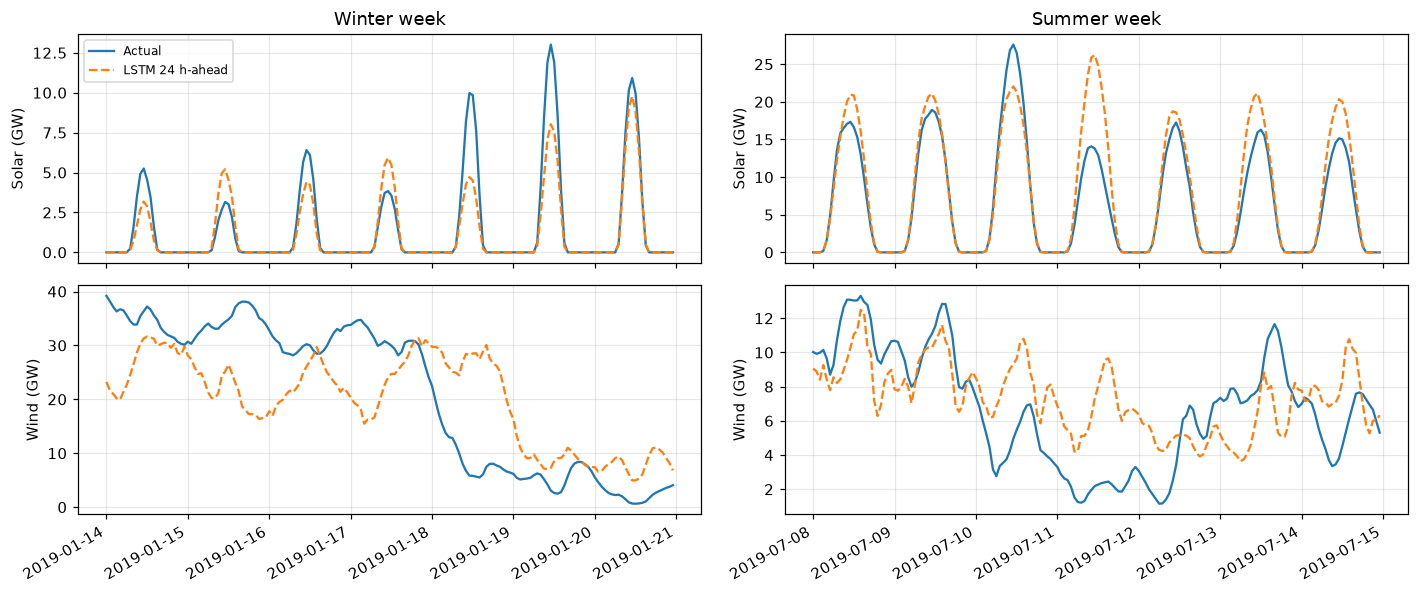

In [8]:
fc = pd.read_csv(cfg.FORECAST_CSV, index_col=0, parse_dates=True)
h = cfg.FORECAST_HORIZON_FOR_DISPATCH
fig, axes = plt.subplots(2, 2, figsize=(13, 5.5), sharex="col")
for j, (season, start) in enumerate(cfg.WEEKS.items()):
    idx = pd.date_range(start, periods=cfg.DISPATCH_HOURS, freq="h")
    w = fc.reindex(idx)
    for i, s in enumerate(cfg.TARGETS):
        ax = axes[i, j]
        ax.plot(idx, w[f"{s}_actual_mw"] / 1e3, label="Actual")
        ax.plot(idx, w[f"{s}_fc_h{h}_mw"] / 1e3, "--", label=f"LSTM {h} h-ahead")
        ax.set_ylabel(f"{s.capitalize()} (GW)")
        if i == 0: ax.set_title(f"{season.capitalize()} week")
axes[0, 0].legend(fontsize=8); fig.autofmt_xdate(); plt.tight_layout(); plt.show()


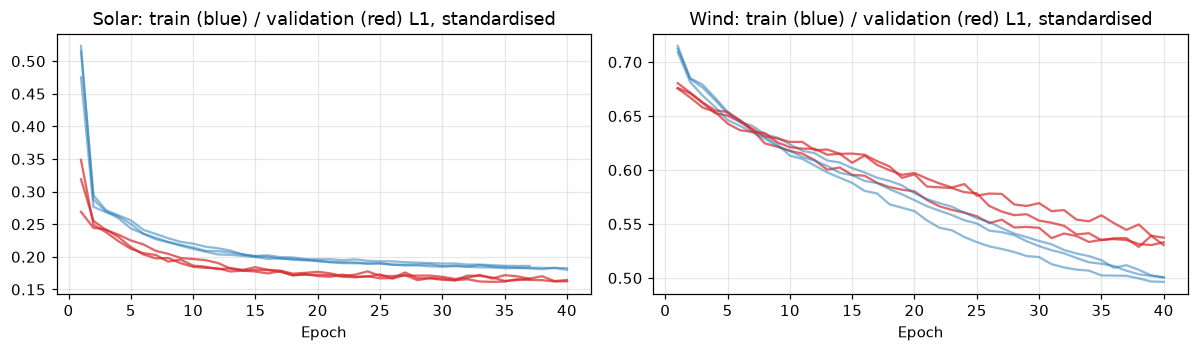

In [9]:
log = pd.read_csv(cfg.OUTPUT_DIR / "training_log.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), sharey=False)
for ax, tag in zip(axes, cfg.TARGETS):
    for seed, d in log[log.model == tag].groupby("seed"):
        ax.plot(d.epoch, d.train_loss, color="tab:blue", alpha=0.5)
        ax.plot(d.epoch, d.val_loss, color="tab:red", alpha=0.7)
    ax.set_title(f"{tag.capitalize()}: train (blue) / validation (red) L1, standardised"); ax.set_xlabel("Epoch")
plt.tight_layout(); plt.show()


## **4. Carbon-tax scenarios and the coal-to-gas switch**

In [10]:
res = pd.read_csv(cfg.SCENARIO_CSV)
be = breakeven_tax()
print(f"Analytical break-even tax: {be:.1f} EUR/tCO2")
rows = []
for (week, src), d in res.groupby(["week", "availability"]):
    last_coal = d[d.coal_mwh > 1].carbon_tax.max()
    first_gas = d[d.coal_mwh <= 1].carbon_tax.min()
    rows.append(dict(week=week, availability=src, last_tax_with_coal=last_coal, first_tax_all_gas=first_gas,
                     consistent_with_breakeven=bool(last_coal < be <= first_gas)))
display(pd.DataFrame(rows))


Analytical break-even tax: 33.1 EUR/tCO2


,week,availability,last_tax_with_coal,first_tax_all_gas,consistent_with_breakeven
0,summer,actual,30,40,True
1,summer,forecast,30,40,True
2,winter,actual,30,40,True
3,winter,forecast,30,40,True


In [11]:
view = res[(res.availability == "forecast") & res.carbon_tax.isin([0, 30, 40, 100, 200])]
display(view[["week", "carbon_tax", "coal_mwh", "gas_mwh", "solar_mwh", "wind_mwh", "emissions_tco2",
              "carbon_cost_eur", "objective_eur", "mean_price_eur_mwh"]].round(0).reset_index(drop=True))


,week,carbon_tax,coal_mwh,gas_mwh,solar_mwh,wind_mwh,emissions_tco2,carbon_cost_eur,objective_eur,mean_price_eur_mwh
0,winter,0,"69,821.00",0.00,"3,346.00","20,482.00","67,826.00",0.00,"2,094,622.00",30.00
1,winter,30,"69,821.00",0.00,"3,346.00","20,482.00","67,826.00","2,034,776.00","4,129,398.00",59.00
2,winter,40,0.00,"69,821.00","3,346.00","20,482.00","25,643.00","1,025,730.00","4,516,767.00",65.00
3,winter,100,0.00,"69,821.00","3,346.00","20,482.00","25,643.00","2,564,325.00","6,055,363.00",87.00
4,winter,200,0.00,"69,821.00","3,346.00","20,482.00","25,643.00","5,128,651.00","8,619,688.00",123.00
5,summer,0,"52,301.00",0.00,"21,124.00","7,449.00","50,806.00",0.00,"1,569,019.00",30.00
6,summer,30,"52,301.00",0.00,"21,124.00","7,449.00","50,806.00","1,524,190.00","3,093,210.00",59.00
7,summer,40,0.00,"52,301.00","21,124.00","7,449.00","19,209.00","768,344.00","3,383,376.00",65.00
8,summer,100,0.00,"52,301.00","21,124.00","7,449.00","19,209.00","1,920,860.00","4,535,892.00",87.00
9,summer,200,0.00,"52,301.00","21,124.00","7,449.00","19,209.00","3,841,720.00","6,456,753.00",123.00


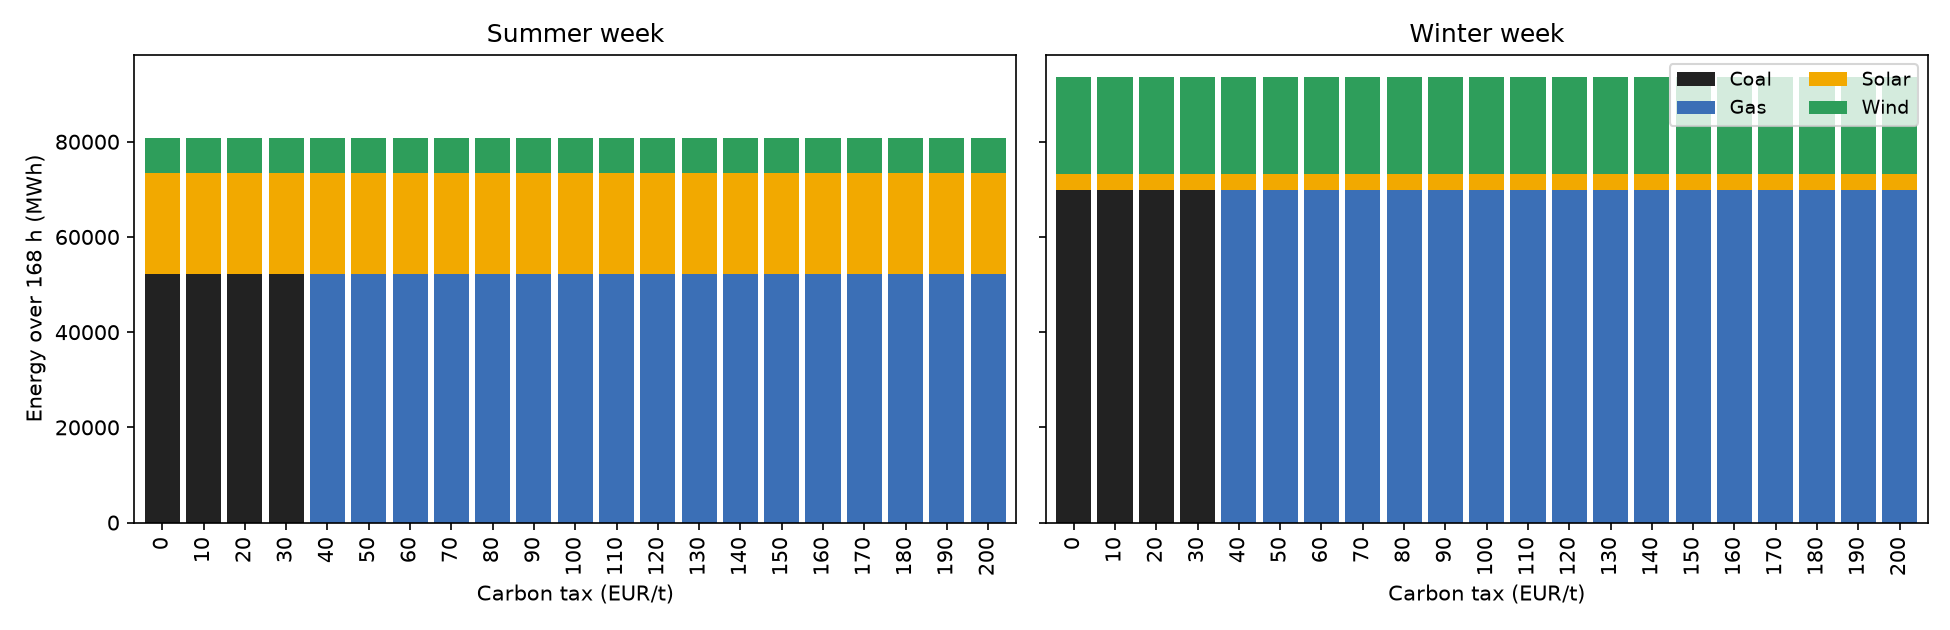

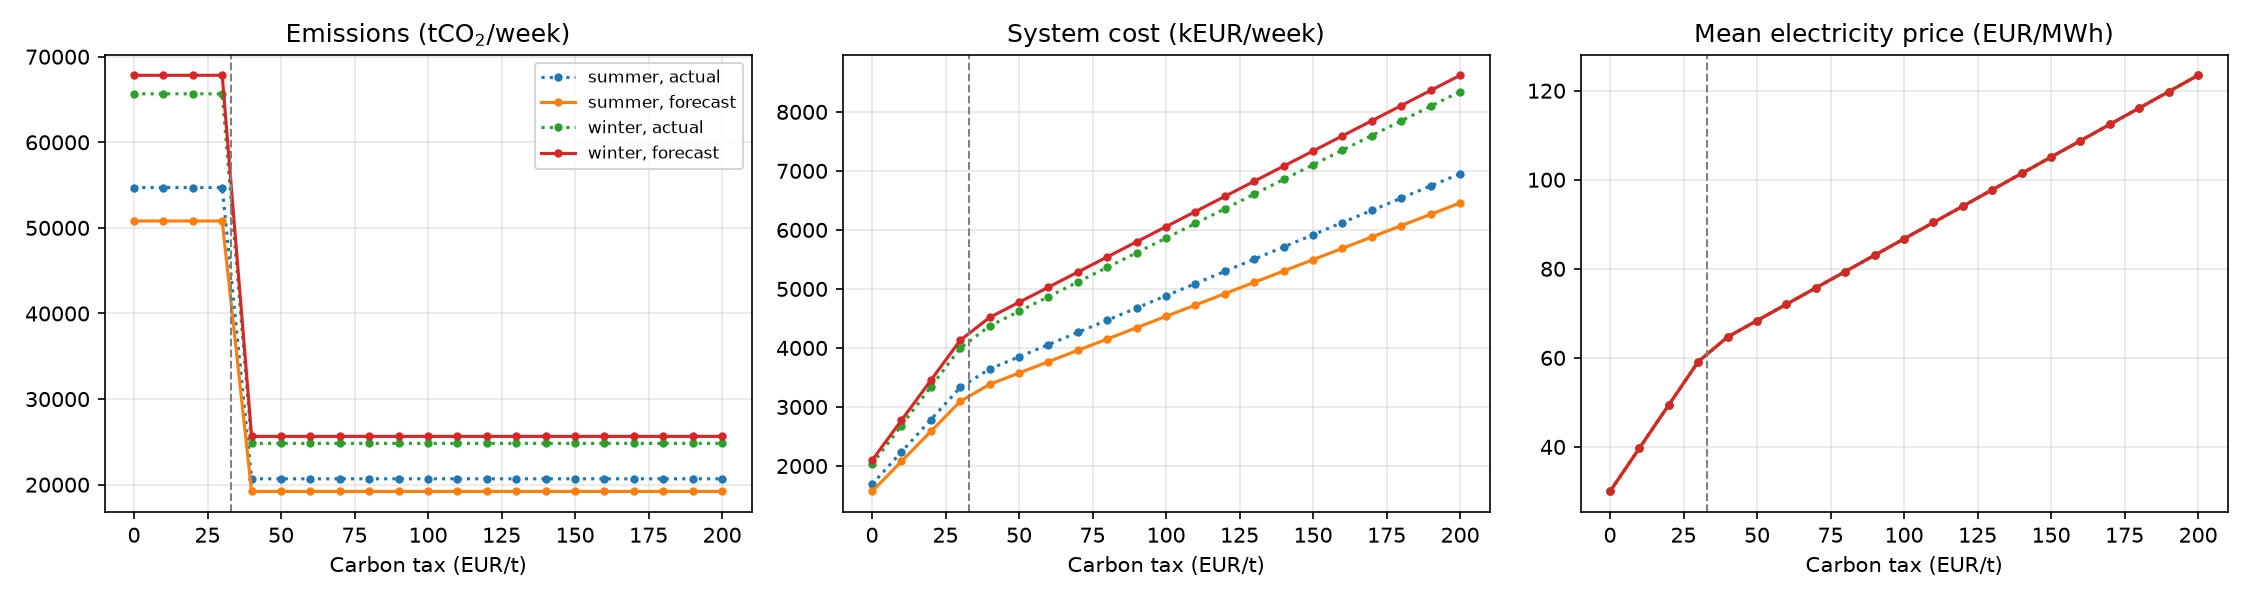

In [12]:
from IPython.display import Image, display as show
for f in ["generation_mix_vs_tax.png", "emissions_cost_vs_tax.png"]:
    show(Image(cfg.FIG_DIR / f))


## **5. Forecast-driven vs perfect-foresight dispatch**

In [13]:
pivot = res[res.carbon_tax.isin([0, 50])].pivot_table(
    index=["week", "carbon_tax"], columns="availability",
    values=["solar_mwh", "wind_mwh", "emissions_tco2", "objective_eur"])
display(pivot.round(0))
rn = (res[res.availability == "forecast"].set_index(["week", "carbon_tax"])[["solar_mwh", "wind_mwh"]].sum(axis=1)
      - res[res.availability == "actual"].set_index(["week", "carbon_tax"])[["solar_mwh", "wind_mwh"]].sum(axis=1))
print("Renewable energy used, forecast minus actual availability (MWh), by week:")
print(rn.groupby("week").mean().round(0))


emissions_tco2           objective_eur               \
availability              actual  forecast        actual     forecast   
week   carbon_tax                                                       
summer 0               54,710.00 50,806.00  1,689,579.00 1,569,019.00   
       50              20,685.00 19,209.00  3,850,192.00 3,575,462.00   
winter 0               65,660.00 67,826.00  2,027,740.00 2,094,622.00   
       50              24,824.00 25,643.00  4,620,789.00 4,773,200.00   

                  solar_mwh            wind_mwh            
availability         actual  forecast    actual  forecast  
week   carbon_tax                                          
summer 0          17,773.00 21,124.00  6,781.00  7,449.00  
       50         17,773.00 21,124.00  6,781.00  7,449.00  
winter 0           4,269.00  3,346.00 21,788.00 20,482.00  
       50          4,269.00  3,346.00 21,788.00 20,482.00

Renewable energy used, forecast minus actual availability (MWh), by week:
week
summer    4,019.00
winter   -2,229.00
dtype: float64


The optimiser uses whatever renewable availability it is told about. Differences between the forecast-driven and
perfect-foresight columns therefore show how forecast error propagates into *planned* dispatch. They are not
a realised-cost comparison.

## **6. Verification checks**

In [14]:
hourly = pd.read_csv(cfg.DISPATCH_CSV, parse_dates=["snapshot"])
supply = hourly[["coal", "gas", "solar", "wind", "battery_discharge"]].sum(axis=1) - hourly["battery_charge"]
max_err = (supply - hourly["demand"]).abs().max()
print(f"Max hourly power imbalance across all stored dispatches: {max_err:.1e} MW")
# tolerance reflects the 3-decimal rounding used when the CSV files were written
assert max_err < 5e-3

# energy balance at weekly level in the scenario table
bal = (res.coal_mwh + res.gas_mwh + res.solar_mwh + res.wind_mwh + res.battery_discharge_mwh
       - res.battery_charge_mwh - res.demand_mwh).abs().max()
print(f"Max weekly energy imbalance: {bal:.1e} MWh")
assert bal < 1e-2

# electric cost parameters
print(f"Gas  marginal cost at tax 0: {thermal_cost(cfg.GAS, 0):.1f} EUR/MWh, {emissions_per_mwh_el(cfg.GAS):.3f} tCO2/MWh_el")
print(f"Coal marginal cost at tax 0: {thermal_cost(cfg.COAL, 0):.1f} EUR/MWh, {emissions_per_mwh_el(cfg.COAL):.3f} tCO2/MWh_el")


Max hourly power imbalance across all stored dispatches: 1.0e-03 MW
Max weekly energy imbalance: 1.0e-03 MWh
Gas  marginal cost at tax 0: 50.0 EUR/MWh, 0.367 tCO2/MWh_el
Coal marginal cost at tax 0: 30.0 EUR/MWh, 0.971 tCO2/MWh_el


## **7. High-renewables sensitivity (battery role)**

In [15]:
sens = pd.read_csv(cfg.SENSITIVITY_CSV)
display(sens[["week", "re_scale", "carbon_tax", "coal_mwh", "gas_mwh", "curtailed_mwh", "battery_discharge_mwh",
              "emissions_tco2", "mean_price_eur_mwh"]].round(0).reset_index(drop=True))


,week,re_scale,carbon_tax,coal_mwh,gas_mwh,curtailed_mwh,battery_discharge_mwh,emissions_tco2,mean_price_eur_mwh
0,winter,1,0,"69,821.00",0.00,0.00,0.00,"67,826.00",30.00
1,winter,1,50,0.00,"69,821.00",0.00,0.00,"25,643.00",68.00
2,winter,1,100,0.00,"69,821.00",0.00,0.00,"25,643.00",87.00
3,winter,3,0,"22,500.00",0.00,0.00,"1,429.00","21,857.00",27.00
4,winter,3,50,0.00,"22,500.00",0.00,"1,429.00","8,264.00",64.00
5,winter,3,100,0.00,"22,500.00",0.00,"1,429.00","8,264.00",82.00
6,winter,6,0,0.00,0.00,"48,277.00","4,445.00",0.00,2.00
7,winter,6,50,0.00,0.00,"48,277.00","4,445.00",0.00,2.00
8,winter,6,100,0.00,0.00,"48,277.00","4,445.00",0.00,2.00
9,summer,1,0,"52,301.00",0.00,0.00,0.00,"50,806.00",30.00


## **Summary**

The conclusions are stated, with numbers, in the README (*Results* and *Limitations*). The checks above confirm that the
dispatch results are internally consistent: the energy balance closes in every stored hour and the simulated fuel switch
brackets the analytical break-even tax.